# 06 · Final pipeline

Builds on the comparisons in 02–05, where YOLOv8s at 1280 px was the best detector. Each stage changes **one** thing
and is scored on all val frames with the same metric, so the effect of data / inference changes is kept apart from
the effect of model changes:

| stage | what changes | training? |
|---|---|---|
| `inference` | inference strategy on the fixed `yolov8s_1280` weights: higher input size, TTA, tiles (SAHI-style) | no |
| `temporal` | post-processing that uses neighbouring frames (bonus: data temporality) | no |
| `ensemble` | Weighted Boxes Fusion of YOLO and Faster R-CNN predictions | no |
| `nomask` | data: train without painting ignored regions | yes |
| `yolov8m_1280` | model: YOLOv8m instead of YOLOv8s, same protocol | yes |
| `final` | best model, trained longer, with the best inference and post-processing | yes |

Inputs to attach (Add Input → Your Work): the output of `02_yolo` that contains `runs/yolov8s_1280`, and the output of
`03_faster_rcnn` (for the ensemble).

In [1]:
!pip install -q ultralytics ensemble-boxes
import os, urllib.request
REPO = "https://raw.githubusercontent.com/MakcDutch/AI-homework2/main/"
for f in ["common.py", "pipeline.py"]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(REPO + f, f)

In [2]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from ultralytics import YOLO
import common as C
import pipeline as P

ROOT = C.find_data_root()
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("work")
os.makedirs(WORK, exist_ok=True)
LOG = f"{WORK}/pipeline_results.csv"
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
torch 2.11.0+cu130 | GPU: Tesla T4


## Configuration
`STAGES` selects what runs in this session (one Kaggle session = 12 h max). `FINAL` is filled in after the
comparison stages.

In [3]:
TRAIN_STEP = 5
EPOCHS = 12
DEVICE = 0
BASE_EXP = "yolov8s_1280"

STAGES = ["inference", "temporal", "ensemble", "nomask"]

FINAL = dict(model="yolov8m.pt", imgsz=1280, batch=4, epochs=30, train_step=5,
             strategy="tiles_1280", temporal_alpha=0.4)

In [4]:
val_paths = C.list_frames(ROOT, "val")["image"].tolist()
test_paths = C.list_frames(ROOT, "test")["image"].tolist()
sizes = {**P.image_sizes(ROOT, "val"), **P.image_sizes(ROOT, "test")}

STRATEGIES = {
    "plain_1280": lambda m, p, sz=1280: C.ultralytics_predict(m, p, imgsz=sz, device=DEVICE),
    "plain_1536": lambda m, p, sz=1280: C.ultralytics_predict(m, p, imgsz=int(sz * 1.2), device=DEVICE, batch=8),
    "tta_1280":   lambda m, p, sz=1280: C.ultralytics_predict(m, p, imgsz=sz, device=DEVICE, augment=True, batch=8),
    "tiles_1280": lambda m, p, sz=1280: P.tiled_predict(m, p, imgsz=sz, device=DEVICE),
}


def log(stage, exp, val_preds, ms=None, **extra):
    metrics, _ = C.coco_evaluate(val_preds, ROOT, "val")
    row = dict(stage=stage, exp=exp, ms_per_img=None if ms is None else round(ms, 1), **extra, **metrics)
    C.results_table(LOG, row)
    print(exp, metrics)
    return metrics["mAP"]


def submit(name, val_preds, test_preds):
    C.save_preds(val_preds, f"{WORK}/val_preds_{name}.pkl")
    C.save_preds(test_preds, f"{WORK}/test_preds_{name}.pkl")
    C.make_submission(test_preds, ROOT, f"{WORK}/sub_{name}.csv")


def train_yolo(name, model, imgsz, epochs, batch, train_step=TRAIN_STEP, mask_ignore=True):
    # same training call as 02_yolo; Ultralytics accumulates gradients to a nominal batch of 64,
    # so a smaller `batch` for a bigger model keeps the effective batch size
    data_dir = f"/tmp/yolo_data_step{train_step}" + ("" if mask_ignore else "_nomask")
    data_yaml = C.build_yolo_dataset(ROOT, data_dir, train_step=train_step, val_step=5, mask_ignore=mask_ignore)
    m = YOLO(model)
    t0 = time.time()
    m.train(data=data_yaml, imgsz=imgsz, epochs=epochs, batch=batch, device=DEVICE, seed=C.SEED, workers=4,
            project=f"{WORK}/runs", name=name, exist_ok=True, verbose=False)
    return YOLO(f"{m.trainer.save_dir}/weights/best.pt"), round((time.time() - t0) / 3600, 2)

## A. Inference strategies on fixed weights
The `yolov8s_1280` weights from `02_yolo` are reused, so only the way predictions are produced changes.

In [5]:
if "inference" in STAGES:
    base = YOLO(P.find_input(f"**/runs/{BASE_EXP}/weights/best.pt"))
    val_by_strategy = {}
    for s, fn in STRATEGIES.items():
        preds, ms = fn(base, val_paths)
        val_by_strategy[s] = preds
        log("inference", f"{BASE_EXP}+{s}", preds, ms)
    scores = C.results_table(LOG).query("stage == 'inference'").set_index("exp")["mAP"]
    BEST_STRATEGY = scores.idxmax().split("+")[1]
    print("best strategy on val:", BEST_STRATEGY)
    best_val = val_by_strategy[BEST_STRATEGY]
    best_test, _ = STRATEGIES[BEST_STRATEGY](base, test_paths)
    submit(f"{BASE_EXP}_{BEST_STRATEGY}", best_val, best_test)

yolov8s_1280+plain_1280 {'mAP': 0.2096, 'AP50': 0.4115, 'AP75': 0.1951, 'AP_small': 0.1119, 'AP_medium': 0.194, 'AP_large': 0.3632}
yolov8s_1280+plain_1536 {'mAP': 0.2154, 'AP50': 0.4271, 'AP75': 0.1987, 'AP_small': 0.12, 'AP_medium': 0.1975, 'AP_large': 0.3642}
yolov8s_1280+tta_1280 {'mAP': 0.2146, 'AP50': 0.4121, 'AP75': 0.2043, 'AP_small': 0.1173, 'AP_medium': 0.1989, 'AP_large': 0.3704}
yolov8s_1280+tiles_1280 {'mAP': 0.2076, 'AP50': 0.4254, 'AP75': 0.1815, 'AP_small': 0.1149, 'AP_medium': 0.1929, 'AP_large': 0.3545}
best strategy on val: plain_1536
saved /kaggle/working/sub_yolov8s_1280_plain_1536.csv: 3811 rows, 3811 with detections


## B. Temporal post-processing (bonus: data temporality)
Detections that are confirmed by an overlapping same-class box in the previous / next frame get a higher score,
isolated ones a lower score. `alpha` is chosen on val.

In [6]:
if "temporal" in STAGES:
    for alpha in [0.2, 0.4, 0.6]:
        log("temporal", f"{BASE_EXP}+{BEST_STRATEGY}+temporal{alpha}", P.temporal_rescore(best_val, alpha), alpha=alpha)
    t = C.results_table(LOG).query("stage == 'temporal'").set_index("alpha")["mAP"]
    BEST_ALPHA = float(t.idxmax())
    submit(f"{BASE_EXP}_{BEST_STRATEGY}_temporal", P.temporal_rescore(best_val, BEST_ALPHA),
           P.temporal_rescore(best_test, BEST_ALPHA))

/kaggle/working/common.py:223: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df[df.get("exp", pd.Series(dtype=str)) != row["exp"]] if len(df) else df,


yolov8s_1280+plain_1536+temporal0.2 {'mAP': 0.2159, 'AP50': 0.4249, 'AP75': 0.2009, 'AP_small': 0.1211, 'AP_medium': 0.1973, 'AP_large': 0.368}


/kaggle/working/common.py:223: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df[df.get("exp", pd.Series(dtype=str)) != row["exp"]] if len(df) else df,


yolov8s_1280+plain_1536+temporal0.4 {'mAP': 0.2124, 'AP50': 0.4142, 'AP75': 0.2003, 'AP_small': 0.1196, 'AP_medium': 0.1935, 'AP_large': 0.3672}


/kaggle/working/common.py:223: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df[df.get("exp", pd.Series(dtype=str)) != row["exp"]] if len(df) else df,


yolov8s_1280+plain_1536+temporal0.6 {'mAP': 0.2042, 'AP50': 0.3925, 'AP75': 0.196, 'AP_small': 0.1144, 'AP_medium': 0.1846, 'AP_large': 0.3616}
saved /kaggle/working/sub_yolov8s_1280_plain_1536_temporal.csv: 3811 rows, 3811 with detections


## C. Ensemble with Faster R-CNN (Weighted Boxes Fusion)

In [7]:
if "ensemble" in STAGES:
    fr_val = C.load_preds(P.find_input("**/val_preds_frcnn_base.pkl"))
    fr_test = C.load_preds(P.find_input("**/test_preds_frcnn_base.pkl"))
    for w in [(2, 1), (1, 1)]:
        ens = P.wbf_ensemble([best_val, fr_val], list(w), sizes)
        log("ensemble", f"WBF yolo:frcnn={w[0]}:{w[1]}", ens, weights=f"{w[0]}:{w[1]}")
    e = C.results_table(LOG).query("stage == 'ensemble'").set_index("weights")["mAP"]
    w = tuple(int(v) for v in e.idxmax().split(":"))
    submit("wbf_yolo_frcnn", P.wbf_ensemble([best_val, fr_val], list(w), sizes),
           P.wbf_ensemble([best_test, fr_test], list(w), sizes))

/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.027350127696990967, 1.0, 0.04211730137467384, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.027448713779449463, 1.0, 0.04193763807415962, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.027466634288430214, 1.0, 0.04196672514081001, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.02768755704164505, 1.0, 0.0415622852742672, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/kaggle/working/common.py:223: FutureWarning: The behavior of 

WBF yolo:frcnn=2:1 {'mAP': 0.2369, 'AP50': 0.4631, 'AP75': 0.2157, 'AP_small': 0.124, 'AP_medium': 0.2098, 'AP_large': 0.4085}


/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.027350127696990967, 1.0, 0.04211730137467384, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.027448713779449463, 1.0, 0.04193763807415962, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.027466634288430214, 1.0, 0.04196672514081001, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.02768755704164505, 1.0, 0.0415622852742672, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/kaggle/working/common.py:223: FutureWarning: The behavior of 

WBF yolo:frcnn=1:1 {'mAP': 0.2348, 'AP50': 0.4572, 'AP75': 0.214, 'AP_small': 0.1189, 'AP_medium': 0.2076, 'AP_large': 0.4082}


/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.027350127696990967, 1.0, 0.04211730137467384, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.027448713779449463, 1.0, 0.04193763807415962, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.027466634288430214, 1.0, 0.04196672514081001, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.02768755704164505, 1.0, 0.0415622852742672, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensembl

saved /kaggle/working/sub_wbf_yolo_frcnn.csv: 3811 rows, 3811 with detections


## D. Data strategy: no masking of ignored regions
Same model and protocol as `yolov8s_1280` in `02_yolo` (val mAP there: see the results table), only the training
frames differ: ignored regions are left as they are.

In [8]:
if "nomask" in STAGES:
    model, hours = train_yolo("yolov8s_1280_nomask", "yolov8s.pt", 1280, EPOCHS, 8, mask_ignore=False)
    v, ms = STRATEGIES["plain_1280"](model, val_paths)
    log("data", "yolov8s_1280_nomask+plain_1280", v, ms, train_hours=hours)
    t, _ = STRATEGIES["plain_1280"](model, test_paths)
    submit("yolov8s_1280_nomask", v, t)

train: 4868 frames from 56 clips (step 5)
val: 571 frames from 7 clips (step 5)
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/yolo_data_step5_nomask/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosai

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/12      9.88G      1.536     0.9508      1.073        519       1280: 100% ━━━━━━━━━━━━ 609/609 2.2it/s 4:31
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.0it/s 12.0s
                   all        571      22906        0.5      0.395      0.409      0.211
Closing dataloader mosaic
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/12      7.44G      1.518     0.9211      1.091        188       1280: 100% ━━━━━━━━━━━━ 609/609 2.4it/s 4:18
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.1it/s 11.7s
                   all        571      22906      0.454       0.41      0.367      0.181

      Epoc

## E. Model change: YOLOv8m, same protocol

In [9]:
if "yolov8m_1280" in STAGES:
    model, hours = train_yolo("yolov8m_1280", "yolov8m.pt", 1280, EPOCHS, 4)
    v, ms = STRATEGIES["plain_1280"](model, val_paths)
    log("model", "yolov8m_1280+plain_1280", v, ms, train_hours=hours)
    t, _ = STRATEGIES["plain_1280"](model, test_paths)
    submit("yolov8m_1280", v, t)

## F. Final model
Chosen from the stages above; trained longer than the 12-epoch comparison budget.

In [10]:
if "final" in STAGES:
    model, hours = train_yolo("final", FINAL["model"], FINAL["imgsz"], FINAL["epochs"], FINAL["batch"],
                              train_step=FINAL["train_step"])
    fn = STRATEGIES[FINAL["strategy"]]
    v, ms = fn(model, val_paths, FINAL["imgsz"])
    log("final", f"final+{FINAL['strategy']}", v, ms, train_hours=hours)
    t, _ = fn(model, test_paths, FINAL["imgsz"])
    submit("final", v, t)
    if FINAL["temporal_alpha"]:
        a = FINAL["temporal_alpha"]
        v2, t2 = P.temporal_rescore(v, a), P.temporal_rescore(t, a)
        log("final", f"final+{FINAL['strategy']}+temporal{a}", v2, alpha=a, train_hours=hours)
        submit("final_temporal", v2, t2)

## Results of this session

,stage,exp,ms_per_img,mAP,AP50,AP75,AP_small,AP_medium,AP_large,alpha,weights,train_hours
0,inference,yolov8s_1280+plain_1280,81.8,0.2096,0.4115,0.1951,0.1119,0.1940,0.3632,NaN,NaN,NaN
1,inference,yolov8s_1280+plain_1536,85.5,0.2154,0.4271,0.1987,0.1200,0.1975,0.3642,NaN,NaN,NaN
2,inference,yolov8s_1280+tta_1280,110.2,0.2146,0.4121,0.2043,0.1173,0.1989,0.3704,NaN,NaN,NaN
3,inference,yolov8s_1280+tiles_1280,376.1,0.2076,0.4254,0.1815,0.1149,0.1929,0.3545,NaN,NaN,NaN
4,temporal,yolov8s_1280+plain_1536+temporal0.2,NaN,0.2159,0.4249,0.2009,0.1211,0.1973,0.3680,0.2,NaN,NaN
5,temporal,yolov8s_1280+plain_1536+temporal0.4,NaN,0.2124,0.4142,0.2003,0.1196,0.1935,0.3672,0.4,NaN,NaN
6,temporal,yolov8s_1280+plain_1536+temporal0.6,NaN,0.2042,0.3925,0.1960,0.1144,0.1846,0.3616,0.6,NaN,NaN
7,ensemble,WBF yolo:frcnn=2:1,NaN,0.2369,0.4631,0.2157,0.1240,0.2098,0.4085,NaN,2:1,NaN
8,ensemble,WBF yolo:frcnn=1:1,NaN,0.2348,0.4572,0.2140,0.1189,0.2076,0.4082,NaN,1:1,NaN
9,data,yolov8s_1280_nomask+plain_1280,68.8,0.2000,0.3933,0.1829,0.0974,0.1838,0.3527,NaN,NaN,0.92


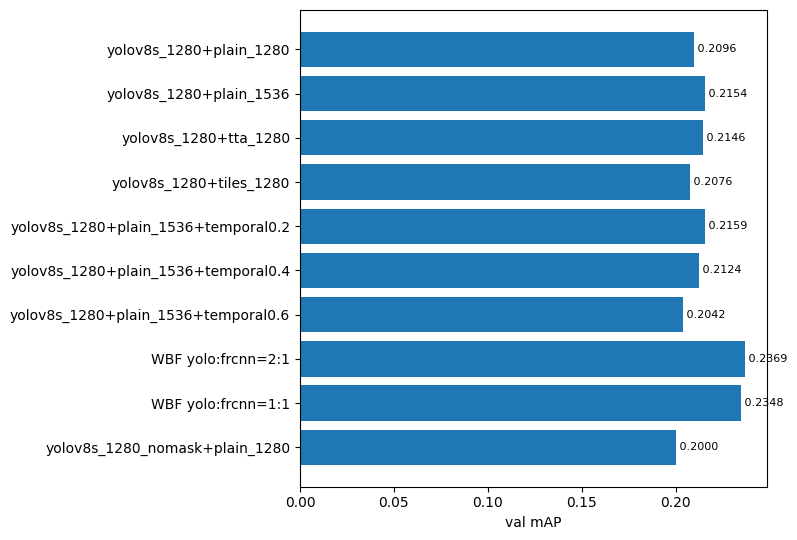

In [11]:
res = C.results_table(LOG)
display(res)
fig, ax = plt.subplots(figsize=(8, 0.45 * len(res) + 1))
ax.barh(res["exp"], res["mAP"]); ax.invert_yaxis(); ax.set_xlabel("val mAP")
for y, v in enumerate(res["mAP"]):
    ax.text(v, y, f" {v:.4f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(f"{WORK}/pipeline_results.png", dpi=120); plt.show()